# 01 – Dataset and Exploratory Data Analysis (EDA)

**Dataset:** UJIIndoorLoc, UCI Machine Learning Repository (CC BY 4.0)

**Goal:** understand the data, check its quality, and spot anything that affects how we build and test models.

**What one row is:** one Wi-Fi scan taken by a phone. It contains the signal strength (RSSI) of 520
access points, the true location (building, floor, longitude, latitude), and who took it, with which phone, and when.

**Note:** we only *look at* the validation file here. We do not use it to make any modelling decisions,
because it is our test set.

**Contents**
1. Loading the data
2. Dataset overview
3. Data quality checks
4. Label distributions
5. Signal strength and locations
6. Users, phones and differences between the two files
7. Summary

## 1. Loading the data

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("..")  # lets us import from the src/ folder
from src.data_loader import load_train, load_validation, WAP_COLS

FIG = "../results/figures/"
METRICS = "../results/metrics/"

# simple plot style and fixed colours
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
BLUE = "#2a78d6"     # train
ORANGE = "#eb6834"   # validation
GREEN = "#1baf7a"
BUILDING_COLORS = [BLUE, ORANGE, GREEN]

In [2]:
train = load_train()
val = load_validation()

# the 520 Wi-Fi signal columns
X_tr = train[WAP_COLS]
X_va = val[WAP_COLS]

print("Train:     ", train.shape)
print("Validation:", val.shape)

Train:      (19937, 529)
Validation: (1111, 529)


In [3]:
# the 9 columns after the Wi-Fi signals
train[["BUILDINGID", "FLOOR", "LONGITUDE", "LATITUDE", "SPACEID",
       "RELATIVEPOSITION", "USERID", "PHONEID", "TIMESTAMP"]].head()

,BUILDINGID,FLOOR,LONGITUDE,LATITUDE,SPACEID,RELATIVEPOSITION,USERID,PHONEID,TIMESTAMP
0,1,2,-7541.2643,4.864921e+06,106,2,2,23,1371713733
1,1,2,-7536.6212,4.864934e+06,106,2,2,23,1371713691
2,1,2,-7519.1524,4.864950e+06,103,2,2,23,1371714095
3,1,2,-7524.5704,4.864934e+06,102,2,2,23,1371713807
4,0,0,-7632.1436,4.864982e+06,122,2,11,13,1369909710


## 2. Dataset overview

| Columns | What they are | How we use them |
|---|---|---|
| `WAP001`–`WAP520` | Signal strength from each access point, from −104 (weak) to 0 (strong). **100 means "not detected"** | Model inputs |
| `BUILDINGID`, `FLOOR` | Building and floor | Targets (classification) |
| `LONGITUDE`, `LATITUDE` | Position in metres | Targets (regression) |
| `SPACEID`, `RELATIVEPOSITION`, `USERID`, `PHONEID`, `TIMESTAMP` | Room, user, phone, time | Not inputs; only for checks |

In [4]:
# number of access points detected in each scan (100 = not detected)
aps_tr = (X_tr != 100).sum(axis=1)
aps_va = (X_va != 100).sum(axis=1)

rows = []
for df, X, aps in [(train, X_tr, aps_tr), (val, X_va, aps_va)]:
    dates = pd.to_datetime(df["TIMESTAMP"], unit="s")
    rows.append({
        "rows": len(df),
        "columns": df.shape[1],
        "buildings": df["BUILDINGID"].nunique(),
        "floors": df["FLOOR"].nunique(),
        "building-floor pairs": len(df.groupby(["BUILDINGID", "FLOOR"])),
        "users": df["USERID"].nunique(),
        "phones": df["PHONEID"].nunique(),
        "first capture": dates.min().date(),
        "last capture": dates.max().date(),
        "% of signal values = 100 (not detected)": round((X == 100).values.mean() * 100, 2),
        "mean APs detected per scan": round(aps.mean(), 1),
        "median APs detected per scan": int(aps.median()),
        "scans with 0 APs detected": int((aps == 0).sum()),
        "exact duplicate rows": int(df.duplicated().sum()),
        "empty (null) values": int(df.isna().sum().sum()),
    })

summary = pd.DataFrame(rows, index=["train", "validation"]).T
summary.to_csv(METRICS + "eda_dataset_summary.csv")
summary

,train,validation
rows,19937,1111
columns,529,529
buildings,3,3
floors,5,5
building-floor pairs,13,13
users,18,1
phones,16,11
first capture,2013-05-30,2013-09-19
last capture,2013-06-20,2013-10-08
% of signal values = 100 (not detected),96.54,96.83


**What this shows**
- There are no empty values, but 96.5% of the signal values are 100, meaning "not detected". So the data is
  very **sparse**: a typical scan picks up only about 17 of the 520 access points.
- The two files were collected months apart, so some differences between them are expected.

## 3. Data quality checks

### 3.1 Are the signal values in the valid range?

In [5]:
# real readings only (remove the 100s)
rssi_tr = X_tr.values.flatten()
rssi_tr = rssi_tr[rssi_tr != 100]
rssi_va = X_va.values.flatten()
rssi_va = rssi_va[rssi_va != 100]

for name, values in [("train", rssi_tr), ("validation", rssi_va)]:
    outside = ((values < -104) | (values > 0)).sum()
    print(f"{name:<11} min = {values.min()}, max = {values.max()}, values outside [-104, 0] = {outside}")

train       min = -104, max = 0, values outside [-104, 0] = 0
validation  min = -102, max = -34, values outside [-104, 0] = 0


All real readings are between −104 and 0 dBm, so there are no corrupted values. Note that 100 is **not** a
strong signal: real signals are always 0 or below, and closer to 0 means stronger.

### 3.2 Are the labels valid?

In [6]:
print("Train buildings:", sorted(train["BUILDINGID"].unique().tolist()), " floors:", sorted(train["FLOOR"].unique().tolist()))
print("Validation buildings:", sorted(val["BUILDINGID"].unique().tolist()), " floors:", sorted(val["FLOOR"].unique().tolist()))
print()
for b in [0, 1, 2]:
    floors_tr = sorted(train[train["BUILDINGID"] == b]["FLOOR"].unique().tolist())
    floors_va = sorted(val[val["BUILDINGID"] == b]["FLOOR"].unique().tolist())
    print(f"Building {b} floors - train: {floors_tr}, validation: {floors_va}")

wrong = train[(train["FLOOR"] == 4) & (train["BUILDINGID"] != 2)]
print("\nRows with floor 4 outside building 2:", len(wrong))

Train buildings: [0, 1, 2]  floors: [0, 1, 2, 3, 4]
Validation buildings: [0, 1, 2]  floors: [0, 1, 2, 3, 4]

Building 0 floors - train: [0, 1, 2, 3], validation: [0, 1, 2, 3]
Building 1 floors - train: [0, 1, 2, 3], validation: [0, 1, 2, 3]
Building 2 floors - train: [0, 1, 2, 3, 4], validation: [0, 1, 2, 3, 4]

Rows with floor 4 outside building 2: 0


In [7]:
# coordinate range of each building
train.groupby("BUILDINGID")[["LONGITUDE", "LATITUDE"]].agg(["min", "max"]).round(1)

LONGITUDE           LATITUDE           
                 min     max        min        max
BUILDINGID                                        
0            -7691.3 -7587.0  4864897.5  4865016.7
1            -7578.5 -7404.5  4864810.0  4864959.5
2            -7415.2 -7300.8  4864745.7  4864861.8

Labels are valid: buildings 0–2, floors 0–4, and floor 4 only exists in building 2 (the only 5-floor building).
The three buildings occupy separate areas.

### 3.3 Duplicates

In [8]:
location = ["BUILDINGID", "FLOOR", "LONGITUDE", "LATITUDE"]

print("Exact duplicate rows in train:      ", train.duplicated().sum())
print("Same signals and same location:     ", train.duplicated(subset=WAP_COLS + location).sum())
print("Same signals, any location:         ", train.duplicated(subset=WAP_COLS).sum())
print("Exact duplicate rows in validation: ", val.duplicated().sum())

# do any identical signal patterns have different building/floor labels? (ignoring empty scans)
dups = train[train.duplicated(subset=WAP_COLS, keep=False) & (aps_tr > 0)]
dups = dups.drop_duplicates(subset=WAP_COLS + ["BUILDINGID", "FLOOR"])
print("Identical signals with conflicting building/floor:", dups.duplicated(subset=WAP_COLS).sum())

Exact duplicate rows in train:       637
Same signals and same location:      754
Same signals, any location:          852
Exact duplicate rows in validation:  0
Identical signals with conflicting building/floor: 0


There are **637 exact duplicate rows** (3.2% of train), probably repeated scans at the same spot. None of them
have conflicting labels, so they are harmless for meaning, but they can make results look better than they are
if copies end up in both the training and testing part of a split. The team should decide whether to drop them.

### 3.4 Scans that detected nothing

In [9]:
empty = train[aps_tr == 0]
print("Train scans with 0 APs:     ", len(empty))
print("Validation scans with 0 APs:", (aps_va == 0).sum())
print()
print(empty.groupby(["USERID", "PHONEID"]).size())

Train scans with 0 APs:      76
Validation scans with 0 APs: 0

USERID  PHONEID
7       6           1
8       1          59
11      13          2
17      22         14
dtype: int64


**76 training scans detected no access point at all**, so they contain no information. **59 of them come from
one user and phone (user 8, phone 1)**, which suggests a faulty recording session. These rows should be removed
from training. Validation has none.

### 3.5 Access points that never appear

In [10]:
seen_tr = (X_tr != 100).any()   # True if the AP was detected at least once
seen_va = (X_va != 100).any()

print("APs seen in train:                  ", seen_tr.sum())
print("APs seen in validation:             ", seen_va.sum())
print("APs never seen in train:            ", (~seen_tr).sum())
print("APs seen in validation but not train:", (seen_va & ~seen_tr).sum())
print("APs seen in train but not validation:", (seen_tr & ~seen_va).sum())

never_seen = [wap for wap in WAP_COLS if not seen_tr[wap]]
print("\nExamples of never-seen APs in train:", never_seen[:8])

APs seen in train:                   465
APs seen in validation:              367
APs never seen in train:             55
APs seen in validation but not train: 55
APs seen in train but not validation: 153

Examples of never-seen APs in train: ['WAP003', 'WAP004', 'WAP092', 'WAP093', 'WAP094', 'WAP095', 'WAP152', 'WAP158']


- **55 access points are never detected in train**. These columns are always 100, so a model learns nothing
  from them and they can be dropped.
- The same 55 **do** appear in validation, and 153 APs seen in train never appear in validation. The Wi-Fi
  setup changed between the two collections.

### 3.6 Extra columns in the validation file

In [11]:
for col in ["SPACEID", "RELATIVEPOSITION", "USERID"]:
    print(f"{col:<17} values in validation: {sorted(val[col].unique().tolist())}")

common_phones = set(train["PHONEID"]) & set(val["PHONEID"])
print("Phones used in both files:", sorted(common_phones))

SPACEID           values in validation: [0]
RELATIVEPOSITION  values in validation: [0]
USERID            values in validation: [0]
Phones used in both files: [13, 14]


In validation, `SPACEID`, `RELATIVEPOSITION` and `USERID` are always 0, so they are just placeholders.
Also, **only 2 of the 11 validation phones (13 and 14) were used in training**. Different phones measure the
same signal differently, so we should expect models to do worse on validation than on training data.

### Section 3 summary

| Check | Result | What to do |
|---|---|---|
| Not-detected values | 96.5% of signal values are 100 | Replace 100 consistently in preprocessing |
| Value range | All real readings within −104 to 0 dBm | Nothing |
| Labels | Valid; floor 4 only in building 2 | Nothing |
| Duplicates | 637 exact duplicates in train | Team decision: drop or keep |
| Empty scans | 76 in train (59 from user 8 / phone 1) | Remove from training |
| Never-detected APs | 55 in train | Drop these columns |
| Phones | Only 2 of 11 validation phones seen in train | Expect lower validation scores |
| Validation placeholders | `USERID`, `SPACEID`, `RELATIVEPOSITION` are 0 | Never use as inputs |

## 4. Label distributions

If one class is much bigger than others, a model can get high accuracy by mostly guessing that class. So we
check how balanced buildings and floors are. Validation is shown only for comparison.

### 4.1 Samples per building

In [12]:
buildings = pd.DataFrame({
    "train": train["BUILDINGID"].value_counts(),
    "validation": val["BUILDINGID"].value_counts(),
}).sort_index()
buildings["train %"] = (buildings["train"] / len(train) * 100).round(1)
buildings["validation %"] = (buildings["validation"] / len(val) * 100).round(1)
buildings

,train,validation,train %,validation %
BUILDINGID,,,,
0,5249,536,26.3,48.2
1,5196,307,26.1,27.6
2,9492,268,47.6,24.1


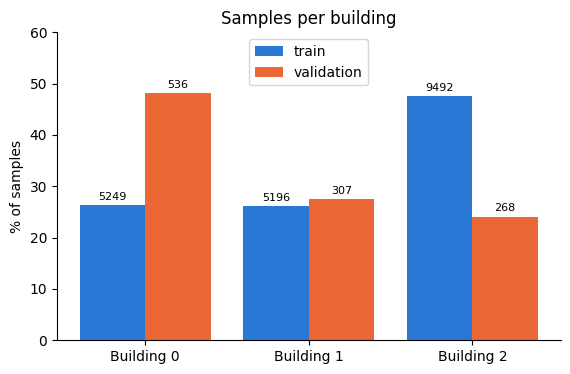

In [13]:
x = np.arange(3)
plt.figure(figsize=(6.5, 4))
plt.bar(x - 0.2, buildings["train %"], width=0.4, color=BLUE, label="train")
plt.bar(x + 0.2, buildings["validation %"], width=0.4, color=ORANGE, label="validation")
for i in range(3):
    plt.text(i - 0.2, buildings["train %"][i] + 1, buildings["train"][i], ha="center", fontsize=8)
    plt.text(i + 0.2, buildings["validation %"][i] + 1, buildings["validation"][i], ha="center", fontsize=8)
plt.xticks(x, ["Building 0", "Building 1", "Building 2"])
plt.ylabel("% of samples")
plt.ylim(0, 60)
plt.title("Samples per building")
plt.legend(loc="upper center")
plt.savefig(FIG + "eda_samples_per_building.png", dpi=200, bbox_inches="tight")
plt.show()

Bars show percentages so the two files can be compared; the numbers on top are counts.
**The files focus on different buildings:** train is mostly building 2 (47.6%), while validation is mostly
building 0 (48.2%). So results should be reported per building, not only overall.

### 4.2 Samples per floor in each building

In [14]:
print("Train (rows = building, columns = floor)")
print(pd.crosstab(train["BUILDINGID"], train["FLOOR"]))
print("\nValidation")
print(pd.crosstab(val["BUILDINGID"], val["FLOOR"]))

Train (rows = building, columns = floor)
FLOOR          0     1     2     3     4
BUILDINGID                              
0           1059  1356  1443  1391     0
1           1368  1484  1396   948     0
2           1942  2162  1577  2709  1102

Validation
FLOOR        0    1    2   3   4
BUILDINGID                      
0           78  208  165  85   0
1           30  143   87  47   0
2           24  111   54  40  39


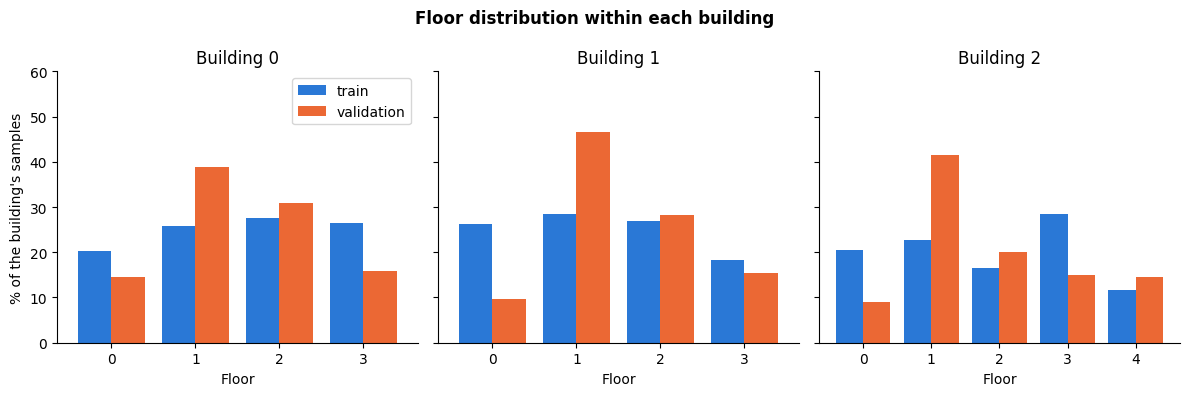

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for b in [0, 1, 2]:
    tr = train[train["BUILDINGID"] == b]["FLOOR"].value_counts(normalize=True) * 100
    va = val[val["BUILDINGID"] == b]["FLOOR"].value_counts(normalize=True) * 100
    floors = pd.DataFrame({"train": tr, "validation": va}).sort_index().fillna(0)
    floors.plot.bar(ax=axes[b], color=[BLUE, ORANGE], width=0.8, rot=0, legend=False)
    axes[b].set_title(f"Building {b}")
    axes[b].set_xlabel("Floor")
axes[0].set_ylabel("% of the building's samples")
axes[0].set_ylim(0, 60)
axes[0].legend(loc="upper right")
plt.suptitle("Floor distribution within each building", fontweight="bold")
plt.tight_layout()
plt.savefig(FIG + "eda_samples_per_floor.png", dpi=200, bbox_inches="tight")
plt.show()

Training floors are fairly even within each building. Validation is much less even: floor 1 alone is 41.6%
of validation, while building 1 floor 0 has only 30 scans and building 2 floor 0 only 24. Scores for those
small groups will be less reliable.

### 4.3 The 13 building–floor combinations

In [16]:
classes = train.groupby(["BUILDINGID", "FLOOR"]).size().to_frame("samples")

# a reference point is a unique position where scans were taken
points = train.drop_duplicates(["BUILDINGID", "FLOOR", "LONGITUDE", "LATITUDE"])
classes["reference points"] = points.groupby(["BUILDINGID", "FLOOR"]).size()
classes["scans per point"] = (classes["samples"] / classes["reference points"]).round(1)
classes["% of train"] = (classes["samples"] / len(train) * 100).round(1)
classes

samples  reference points  scans per point  % of train
BUILDINGID FLOOR                                                        
0          0         1059                54             19.6         5.3
           1         1356                67             20.2         6.8
           2         1443                70             20.6         7.2
           3         1391                68             20.5         7.0
1          0         1368                76             18.0         6.9
           1         1484                60             24.7         7.4
           2         1396                79             17.7         7.0
           3          948                50             19.0         4.8
2          0         1942                67             29.0         9.7
           1         2162                89             24.3        10.8
           2         1577                73             21.6         7.9
           3         2709               113             24.0        13.6
           4         1102                67             16.4         5.5

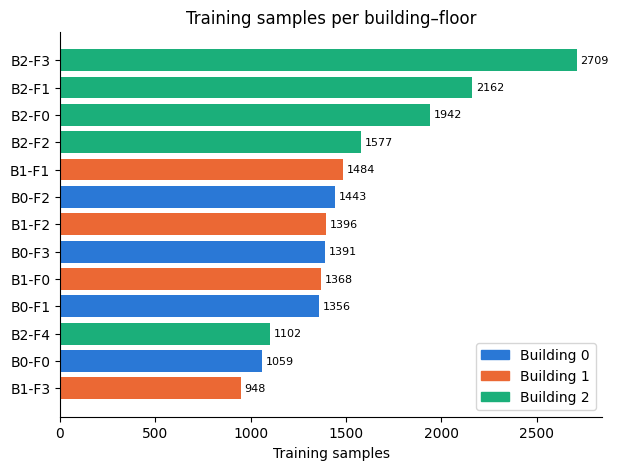

In [17]:
from matplotlib.patches import Patch

sorted_classes = classes.sort_values("samples")
labels = [f"B{b}-F{f}" for b, f in sorted_classes.index]
colors = [BUILDING_COLORS[b] for b, f in sorted_classes.index]

plt.figure(figsize=(7, 5))
plt.barh(labels, sorted_classes["samples"], color=colors)
for i, n in enumerate(sorted_classes["samples"]):
    plt.text(n + 20, i, n, va="center", fontsize=8)
plt.xlabel("Training samples")
plt.title("Training samples per building–floor")
plt.legend(handles=[Patch(color=BUILDING_COLORS[b], label=f"Building {b}") for b in [0, 1, 2]],
           loc="lower right")
plt.savefig(FIG + "eda_building_floor_classes.png", dpi=200, bbox_inches="tight")
plt.show()

### 4.4 How imbalanced are the classes?

In [18]:
rows = []
for name, counts in [("building", train["BUILDINGID"].value_counts()),
                     ("floor", train["FLOOR"].value_counts()),
                     ("building-floor", classes["samples"])]:
    rows.append({
        "target": name,
        "classes": len(counts),
        "largest": counts.max(),
        "smallest": counts.min(),
        "largest / smallest": round(counts.max() / counts.min(), 2),
        "accuracy if always guessing the largest (%)": round(counts.max() / counts.sum() * 100, 1),
    })

imbalance = pd.DataFrame(rows).set_index("target")
imbalance.to_csv(METRICS + "eda_class_imbalance.csv")
imbalance

,classes,largest,smallest,largest / smallest,accuracy if always guessing the largest (%)
target,,,,,
building,3,9492,5196,1.83,47.6
floor,5,5048,1102,4.58,25.3
building-floor,13,2709,948,2.86,13.6


**What this shows**
- The imbalance is **moderate**: every building–floor has at least 948 training scans, and the biggest (B2-F3)
  has about 3 times as many as the smallest (B1-F3). So we should report **macro-F1** as well as accuracy.
- Always guessing the most common class gives 47.6% for building and 25.3% for floor. Any real model must
  beat these numbers by a wide margin.
- Each position was scanned about 16–29 times, so every area is well covered.

## 5. Signal strength and locations

**RSSI** (Received Signal Strength Indicator) is how strong an access point's signal is at the phone, in dBm.
It is negative: −30 is very strong (close by), −100 is very weak (far away). Because signals get weaker with
distance and walls, the pattern of signals tells us where the phone is.

The 100s are left out of all plots below because they are not real measurements.

### 5.1 Distribution of signal strength

In [19]:
rssi_stats = pd.DataFrame({
    "train": pd.Series(rssi_tr).describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]),
    "validation": pd.Series(rssi_va).describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]),
}).round(1)
rssi_stats.to_csv(METRICS + "eda_rssi_stats.csv")
rssi_stats

,train,validation
count,358763.0,18304.0
mean,-78.5,-77.7
std,12.6,12.0
min,-104.0,-102.0
5%,-94.0,-93.0
25%,-88.0,-87.0
50%,-82.0,-80.0
75%,-72.0,-70.8
95%,-54.0,-54.0
max,0.0,-34.0


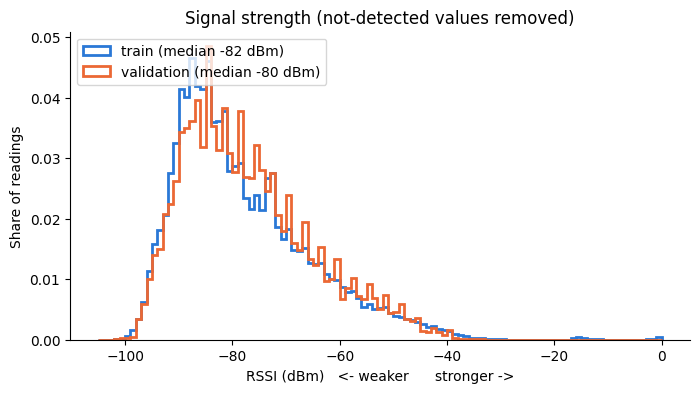

In [20]:
bins = range(-105, 1)
plt.figure(figsize=(8, 4))
plt.hist(rssi_tr, bins=bins, density=True, histtype="step", linewidth=2, color=BLUE,
         label=f"train (median {np.median(rssi_tr):.0f} dBm)")
plt.hist(rssi_va, bins=bins, density=True, histtype="step", linewidth=2, color=ORANGE,
         label=f"validation (median {np.median(rssi_va):.0f} dBm)")
plt.xlabel("RSSI (dBm)   <- weaker      stronger ->")
plt.ylabel("Share of readings")
plt.title("Signal strength (not-detected values removed)")
plt.legend(loc="upper left")
plt.savefig(FIG + "eda_rssi_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

Most readings are weak (median around −80 dBm): a phone hears many far-away access points and only a few close
ones. The weakest real reading is −104 dBm, so in preprocessing **100 should be replaced by a value below −104**
(for example −110). Otherwise a model would think "not detected" is the strongest possible signal.

### 5.2 Access points per scan and strongest signal per scan

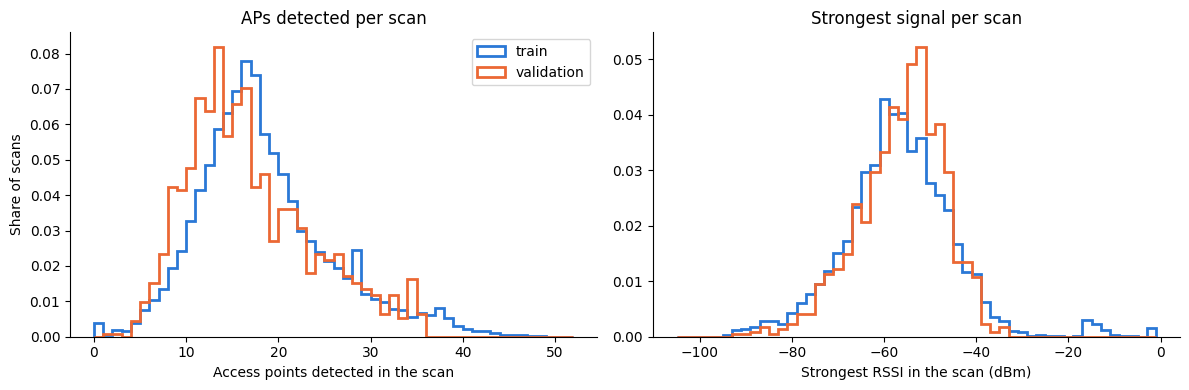

In [21]:
# strongest real signal in each scan (100s turned into empty values first)
strongest_tr = X_tr[X_tr != 100].max(axis=1)
strongest_va = X_va[X_va != 100].max(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(aps_tr, bins=range(0, 53), density=True, histtype="step", linewidth=2, color=BLUE, label="train")
axes[0].hist(aps_va, bins=range(0, 53), density=True, histtype="step", linewidth=2, color=ORANGE, label="validation")
axes[0].set_xlabel("Access points detected in the scan")
axes[0].set_ylabel("Share of scans")
axes[0].set_title("APs detected per scan")
axes[0].legend()

axes[1].hist(strongest_tr, bins=range(-105, 1, 2), density=True, histtype="step", linewidth=2, color=BLUE)
axes[1].hist(strongest_va, bins=range(-105, 1, 2), density=True, histtype="step", linewidth=2, color=ORANGE)
axes[1].set_xlabel("Strongest RSSI in the scan (dBm)")
axes[1].set_title("Strongest signal per scan")
plt.tight_layout()
plt.savefig(FIG + "eda_aps_per_scan.png", dpi=200, bbox_inches="tight")
plt.show()

In [22]:
pd.DataFrame({
    "train: median APs": aps_tr.groupby(train["BUILDINGID"]).median(),
    "validation: median APs": aps_va.groupby(val["BUILDINGID"]).median(),
    "train: median strongest (dBm)": strongest_tr.groupby(train["BUILDINGID"]).median(),
    "validation: median strongest (dBm)": strongest_va.groupby(val["BUILDINGID"]).median(),
})

,train: median APs,validation: median APs,train: median strongest (dBm),validation: median strongest (dBm)
BUILDINGID,,,,
0,16.0,16.0,-55.0,-55.0
1,15.0,13.0,-61.0,-57.0
2,19.0,16.0,-57.0,-55.5


Building 2 detects more access points per scan (median 19) than buildings 0 and 1 (15–16). So simple
features like **"number of APs detected"** and **"strongest signal"** already carry some location information.

### 5.3 Unusually strong readings

The right-hand plot shows a small group of training scans between −20 and 0 dBm, which never happens in
validation (its strongest reading is −34 dBm). Let's see where they come from.

In [23]:
strong = (X_tr > -30) & (X_tr != 100)
scans_with_strong = strong.any(axis=1)

print("Readings stronger than -30 dBm in train:", strong.values.sum(),
      f"in {scans_with_strong.sum()} scans ({scans_with_strong.mean() * 100:.1f}%)")
print("Readings stronger than -30 dBm in validation:", ((X_va > -30) & (X_va != 100)).values.sum())

devices = pd.DataFrame({
    "scans with strong readings": train[scans_with_strong].groupby(["USERID", "PHONEID"]).size(),
    "all scans by this device": train.groupby(["USERID", "PHONEID"]).size(),
}).dropna().astype(int)
devices["% of device's scans"] = (devices.iloc[:, 0] / devices.iloc[:, 1] * 100).round(1)
devices.sort_values("scans with strong readings", ascending=False)

Readings stronger than -30 dBm in train: 775 in 492 scans (2.5%)
Readings stronger than -30 dBm in validation: 0


,,scans with strong readings,all scans by this device,% of device's scans
USERID,PHONEID,,,
6,19,430,980,43.9
14,7,51,1596,3.2
3,16,5,192,2.6
10,8,2,913,0.2
15,11,2,498,0.4
1,14,1,2737,0.0
16,14,1,1032,0.1


**430 of the 492 scans (87%) with these readings come from one device (user 6, phone 19).** So this is a
quirk of that phone, not a real signal. In preprocessing, readings stronger than −30 dBm can be capped at −30.

### 5.4 Where the scans were taken

Unique training positions: 933   validation positions: 1074


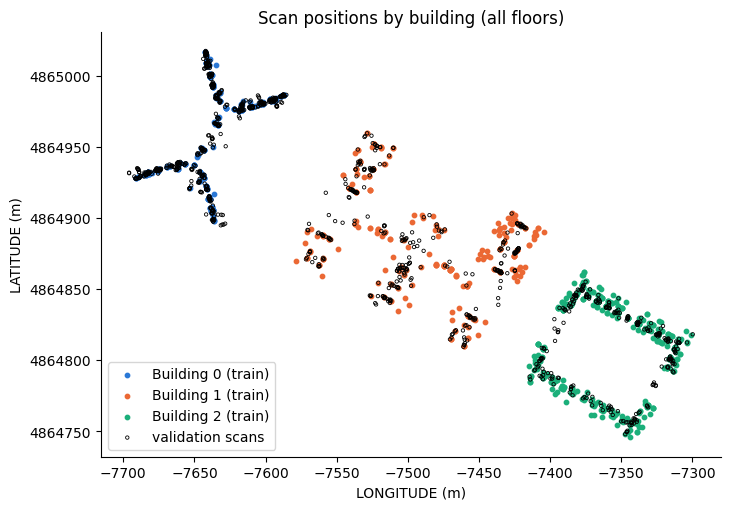

In [37]:
# one dot per unique position keeps the maps readable
points_tr = train.drop_duplicates(["LONGITUDE", "LATITUDE", "FLOOR"])
points_va = val.drop_duplicates(["LONGITUDE", "LATITUDE", "FLOOR"])
print("Unique training positions:", len(points_tr), "  validation positions:", len(points_va))

plt.figure(figsize=(8, 6))
for b in [0, 1, 2]:
    p = points_tr[points_tr["BUILDINGID"] == b]
    plt.scatter(p["LONGITUDE"], p["LATITUDE"], s=10, color=BUILDING_COLORS[b], label=f"Building {b} (train)")
plt.scatter(points_va["LONGITUDE"], points_va["LATITUDE"], s=6, facecolors="none",
            edgecolors="black", linewidths=0.6, label="validation scans")
plt.gca().set_aspect("equal")
plt.ticklabel_format(useOffset=False, style="plain")
plt.xlabel("LONGITUDE (m)")
plt.ylabel("LATITUDE (m)")
plt.title("Scan positions by building (all floors)")
plt.legend(loc="lower left")
plt.savefig(FIG + "eda_map_by_building.png", dpi=200, bbox_inches="tight")
plt.show()

Coordinates are in metres, so distances on the map are real distances and positioning error can be measured
in metres. The buildings are clearly separated, so predicting the building should be the easiest task.

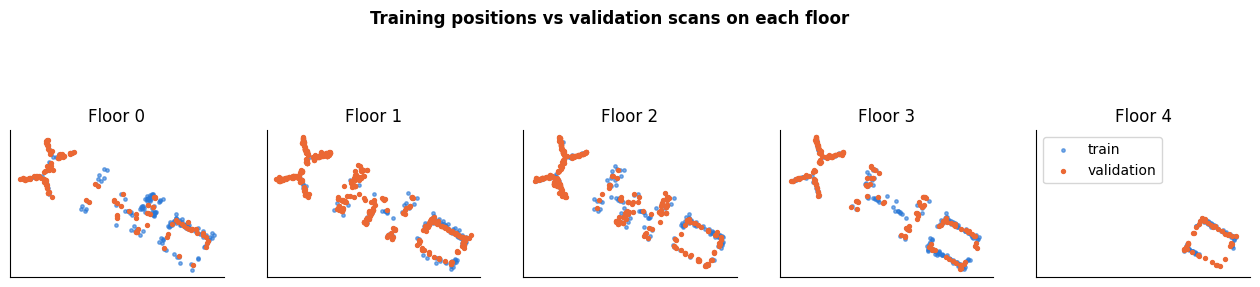

In [25]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4), sharex=True, sharey=True)
for f in range(5):
    t = points_tr[points_tr["FLOOR"] == f]
    v = points_va[points_va["FLOOR"] == f]
    axes[f].scatter(t["LONGITUDE"], t["LATITUDE"], s=6, color=BLUE, alpha=0.6, label="train")
    axes[f].scatter(v["LONGITUDE"], v["LATITUDE"], s=8, color=ORANGE, label="validation")
    axes[f].set_title(f"Floor {f}")
    axes[f].set_aspect("equal")
    axes[f].set_xticks([])
    axes[f].set_yticks([])
axes[4].legend(loc="upper left")
plt.suptitle("Training positions vs validation scans on each floor", fontweight="bold")
plt.savefig(FIG + "eda_map_by_floor.png", dpi=200, bbox_inches="tight")
plt.show()

Next we check how far each validation scan is from the nearest training position on the same floor. This only
describes coverage; it is not used to train or tune anything.

In [26]:
gaps = []
for i, row in val.iterrows():
    same_floor = points_tr[(points_tr["BUILDINGID"] == row["BUILDINGID"]) & (points_tr["FLOOR"] == row["FLOOR"])]
    distance = np.sqrt((same_floor["LONGITUDE"] - row["LONGITUDE"]) ** 2 +
                       (same_floor["LATITUDE"] - row["LATITUDE"]) ** 2)
    gaps.append(distance.min())
gaps = pd.Series(gaps)

print("Distance (m) to the nearest training position on the same floor:")
print(gaps.describe(percentiles=[0.5, 0.9]).round(1))
print(f"\nValidation scans more than 10 m away: {(gaps > 10).sum()} ({(gaps > 10).mean() * 100:.1f}%)")

Distance (m) to the nearest training position on the same floor:
count    1111.0
mean        2.0
std         3.7
min         0.0
50%         0.9
90%         4.6
max        45.7
dtype: float64

Validation scans more than 10 m away: 35 (3.2%)


Most validation scans are very close to a training position (median 0.9 m, 90% within 4.6 m). But
**35 scans (3.2%) are more than 10 m away**, up to 45.7 m. These are likely to have the largest errors.

### 5.5 Wi-Fi coverage across the campus

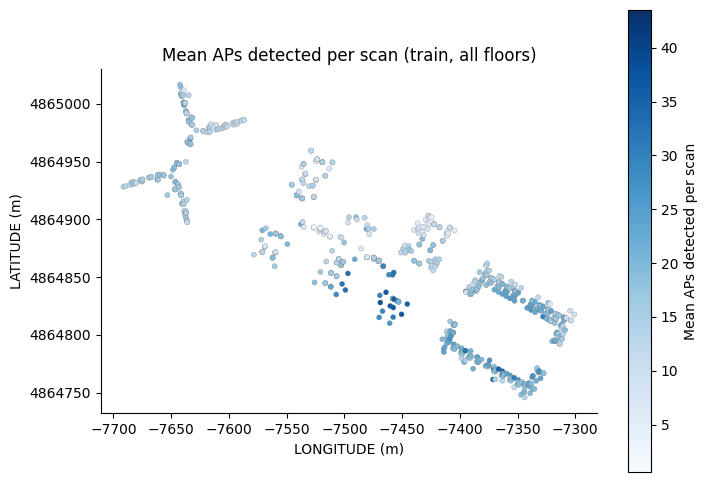

In [27]:
coverage = train[["LONGITUDE", "LATITUDE"]].copy()
coverage["aps"] = aps_tr
coverage = coverage.groupby(["LONGITUDE", "LATITUDE"], as_index=False).mean()

plt.figure(figsize=(8, 6))
plt.scatter(coverage["LONGITUDE"], coverage["LATITUDE"], c=coverage["aps"], cmap="Blues",
            s=14, edgecolors="grey", linewidths=0.2)
plt.colorbar(label="Mean APs detected per scan")
plt.gca().set_aspect("equal")
plt.ticklabel_format(useOffset=False, style="plain")
plt.xlabel("LONGITUDE (m)")
plt.ylabel("LATITUDE (m)")
plt.title("Mean APs detected per scan (train, all floors)")
plt.savefig(FIG + "eda_map_ap_coverage.png", dpi=200, bbox_inches="tight")
plt.show()

Pale dots are places with few detected access points. Coverage varies a lot: part of building 1 detects 35–40
APs per scan, while its northern part detects around 10 or fewer. Locations with weak coverage are harder to
predict accurately.

### Section 5 summary

| Check | Result |
|---|---|
| Signal strength | Median about −80 dBm; weakest real reading −104 dBm → replace 100 with about −110 |
| APs per scan | Median 17 in train, 15 in validation; building 2 has the most |
| Unusually strong readings | 87% come from phone 19 → cap at −30 dBm |
| Validation coverage | Median 0.9 m from a training position; 35 scans more than 10 m away |
| Weak-coverage areas | Northern part of building 1 |

## 6. Users, phones and differences between the two files

These columns are not model inputs, but they tell us how to test models fairly.

### 6.1 Who collected the training data

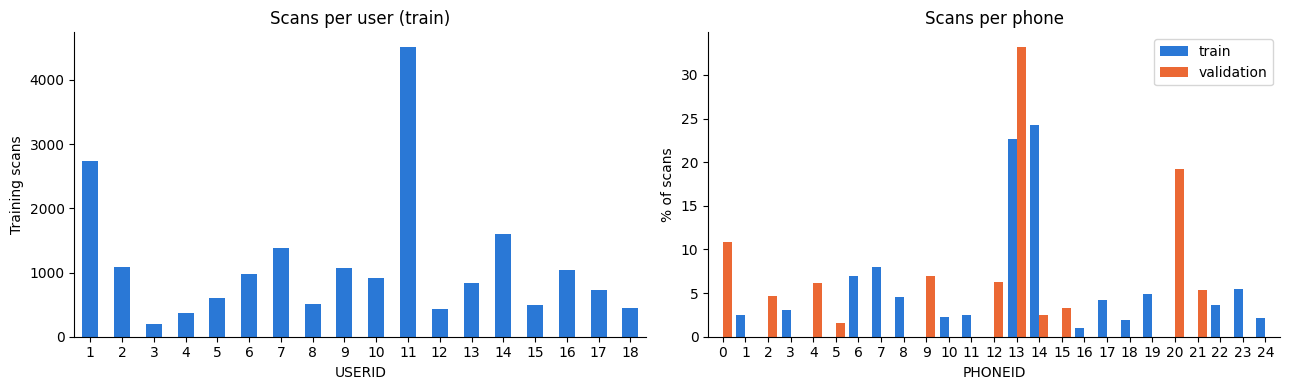

Phones only in train:      [1, 3, 6, 7, 8, 10, 11, 16, 17, 18, 19, 22, 23, 24]
Phones only in validation: [0, 2, 4, 5, 9, 12, 15, 20, 21]
Phones in both:            [13, 14]


In [28]:
users = train["USERID"].value_counts().sort_index()
phones = pd.DataFrame({
    "train": train["PHONEID"].value_counts(normalize=True) * 100,
    "validation": val["PHONEID"].value_counts(normalize=True) * 100,
}).sort_index().fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
users.plot.bar(ax=axes[0], color=BLUE, rot=0)
axes[0].set_xlabel("USERID")
axes[0].set_ylabel("Training scans")
axes[0].set_title("Scans per user (train)")
phones.plot.bar(ax=axes[1], color=[BLUE, ORANGE], width=0.8, rot=0)
axes[1].set_xlabel("PHONEID")
axes[1].set_ylabel("% of scans")
axes[1].set_title("Scans per phone")
plt.tight_layout()
plt.savefig(FIG + "eda_users_and_phones.png", dpi=200, bbox_inches="tight")
plt.show()

print("Phones only in train:     ", sorted(set(train["PHONEID"]) - set(val["PHONEID"])))
print("Phones only in validation:", sorted(set(val["PHONEID"]) - set(train["PHONEID"])))
print("Phones in both:           ", sorted(set(train["PHONEID"]) & set(val["PHONEID"])))

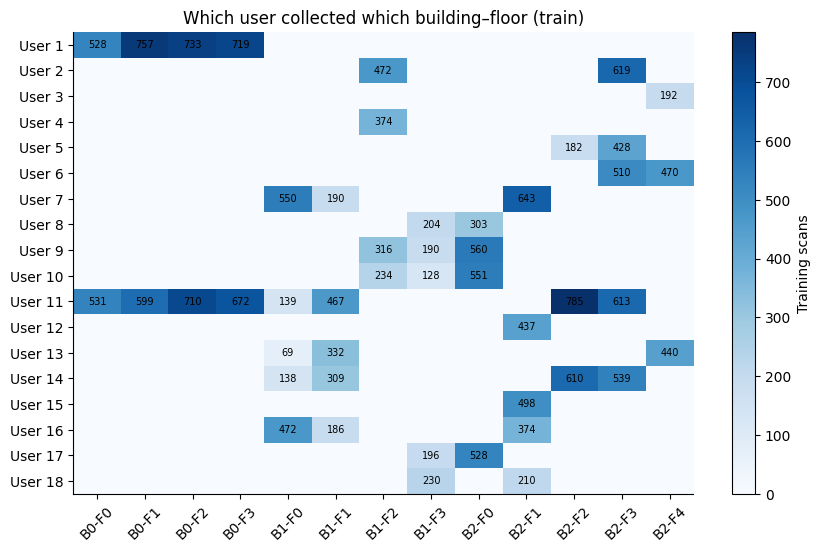

In [29]:
# which building-floor did each user collect?
area = "B" + train["BUILDINGID"].astype(str) + "-F" + train["FLOOR"].astype(str)
user_area = pd.crosstab(train["USERID"], area)

plt.figure(figsize=(10, 6))
plt.imshow(user_area, cmap="Blues", aspect="auto")
plt.colorbar(label="Training scans")
plt.xticks(range(len(user_area.columns)), user_area.columns, rotation=45)
plt.yticks(range(len(user_area.index)), [f"User {u}" for u in user_area.index])
for i in range(len(user_area.index)):
    for j in range(len(user_area.columns)):
        n = user_area.iloc[i, j]
        if n > 0:
            plt.text(j, i, n, ha="center", va="center", fontsize=7)
plt.title("Which user collected which building–floor (train)")
plt.savefig(FIG + "eda_user_coverage.png", dpi=200, bbox_inches="tight")
plt.show()

In [30]:
pd.DataFrame({
    "scans": users,
    "% of train": (users / len(train) * 100).round(1),
    "buildings covered": train.groupby("USERID")["BUILDINGID"].nunique(),
    "building-floors covered": (user_area > 0).sum(axis=1),
    "phones used": train.groupby("USERID")["PHONEID"].nunique(),
})

,scans,% of train,buildings covered,building-floors covered,phones used
USERID,,,,,
1,2737,13.7,1,4,1
2,1091,5.5,2,2,1
3,192,1.0,1,1,1
4,374,1.9,1,1,1
5,610,3.1,1,2,1
6,980,4.9,1,2,1
7,1383,6.9,2,3,1
8,507,2.5,2,2,1
9,1066,5.3,2,3,1


**What this shows**
- Each user collected only a few areas (1 to 8 of the 13 building–floors, most only 1–3).
- Each user used **exactly one phone**, so "user" and "phone" mean the same thing in the training data.
- User 11 alone collected 22.7% of the training data.

So if we test a model on a user it has never seen, we are also testing it on a new phone and partly on new
areas. That is a harder test than the official split.

### 6.2 Differences between phones

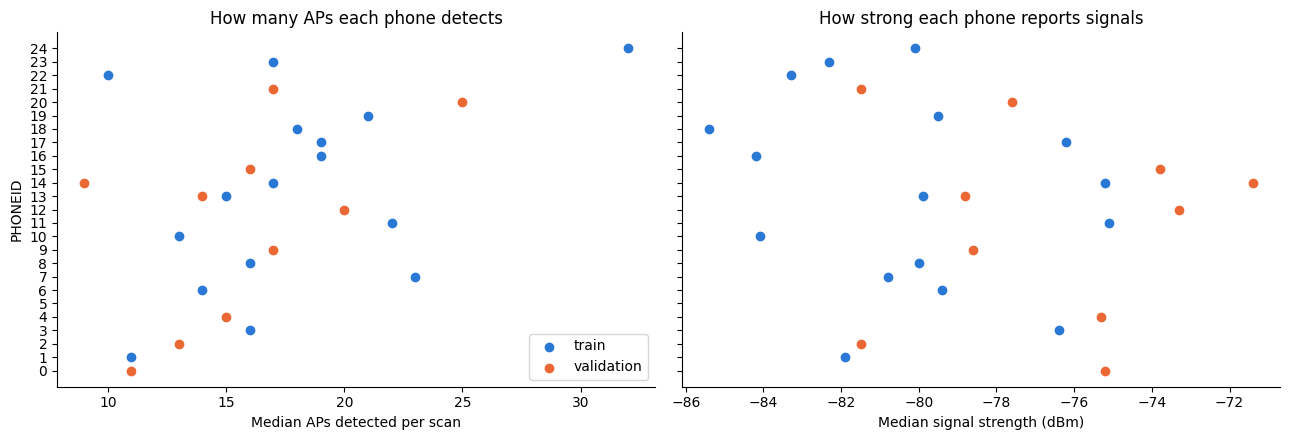

In [31]:
# average real signal strength in each scan
mean_rssi_tr = X_tr[X_tr != 100].mean(axis=1)
mean_rssi_va = X_va[X_va != 100].mean(axis=1)

phone_tr = pd.DataFrame({
    "scans": train["PHONEID"].value_counts(),
    "median APs": aps_tr.groupby(train["PHONEID"]).median(),
    "median signal (dBm)": mean_rssi_tr.groupby(train["PHONEID"]).median().round(1),
})
phone_va = pd.DataFrame({
    "scans": val["PHONEID"].value_counts(),
    "median APs": aps_va.groupby(val["PHONEID"]).median(),
    "median signal (dBm)": mean_rssi_va.groupby(val["PHONEID"]).median().round(1),
})
phone_tr = phone_tr[phone_tr["scans"] >= 20]   # ignore phones with very few scans
phone_va = phone_va[phone_va["scans"] >= 20]
pd.concat([phone_tr.assign(split="train"), phone_va.assign(split="validation")]).to_csv(METRICS + "eda_phone_summary.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
axes[0].scatter(phone_tr["median APs"], phone_tr.index, color=BLUE, label="train")
axes[0].scatter(phone_va["median APs"], phone_va.index, color=ORANGE, label="validation")
axes[1].scatter(phone_tr["median signal (dBm)"], phone_tr.index, color=BLUE)
axes[1].scatter(phone_va["median signal (dBm)"], phone_va.index, color=ORANGE)
axes[0].set_yticks(range(25))
axes[0].set_ylabel("PHONEID")
axes[0].set_xlabel("Median APs detected per scan")
axes[1].set_xlabel("Median signal strength (dBm)")
axes[0].set_title("How many APs each phone detects")
axes[1].set_title("How strong each phone reports signals")
axes[0].legend()
plt.tight_layout()
plt.savefig(FIG + "eda_phone_differences.png", dpi=200, bbox_inches="tight")
plt.show()

Phones differ a lot: depending on the phone, a scan detects a median of about 9 to 32 access points, and the
typical signal strength ranges from about −86 to −71 dBm (a 15 dB difference). A model trained on some phones
can confuse another phone's weaker or stronger readings with a change in location. Features that only say
whether an AP was detected or not (missingness indicators) are less affected by this.

### 6.3 When the data was collected

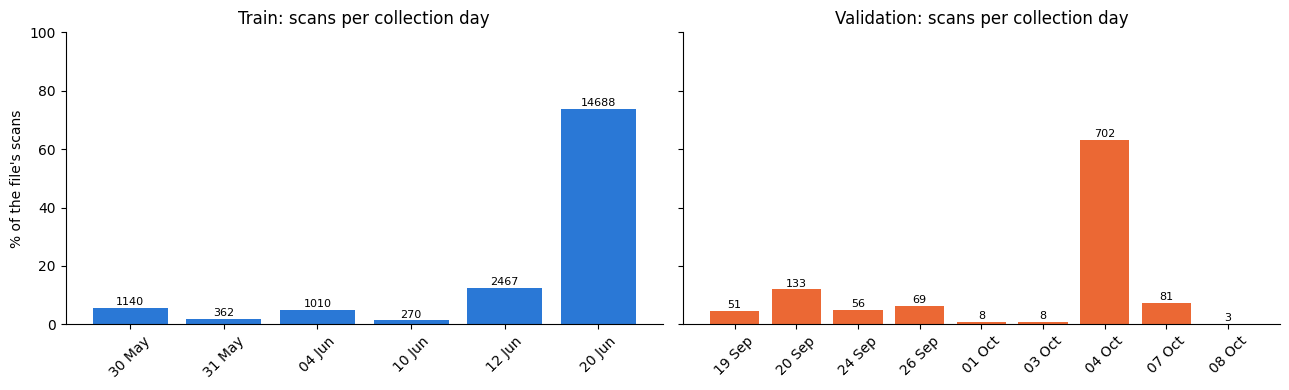

Train collection days:      6 (2013-05-30 to 2013-06-20)
Validation collection days: 9 (2013-09-19 to 2013-10-08)
Gap between the two: 91 days


In [32]:
days_tr = pd.to_datetime(train["TIMESTAMP"], unit="s").dt.date.value_counts().sort_index()
days_va = pd.to_datetime(val["TIMESTAMP"], unit="s").dt.date.value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, days, color, name in [(axes[0], days_tr, BLUE, "Train"), (axes[1], days_va, ORANGE, "Validation")]:
    percent = days / days.sum() * 100
    labels = [d.strftime("%d %b") for d in days.index]
    ax.bar(labels, percent, color=color)
    for i in range(len(days)):
        ax.text(i, percent.iloc[i] + 1, days.iloc[i], ha="center", fontsize=8)
    ax.set_title(f"{name}: scans per collection day")
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("% of the file's scans")
axes[0].set_ylim(0, 100)
plt.tight_layout()
plt.savefig(FIG + "eda_collection_timeline.png", dpi=200, bbox_inches="tight")
plt.show()

print("Train collection days:     ", len(days_tr), f"({days_tr.index.min()} to {days_tr.index.max()})")
print("Validation collection days:", len(days_va), f"({days_va.index.min()} to {days_va.index.max()})")
print("Gap between the two:", (days_va.index.min() - days_tr.index.max()).days, "days")

The two files were collected **91 days apart**. Each is dominated by one big session: 20 June made up 73.7% of
train and 4 October made up 63% of validation. Wi-Fi networks change over time (access points get moved or
replaced), which explains why some access points appear in only one file.

### 6.4 Comparing the signals in the two files

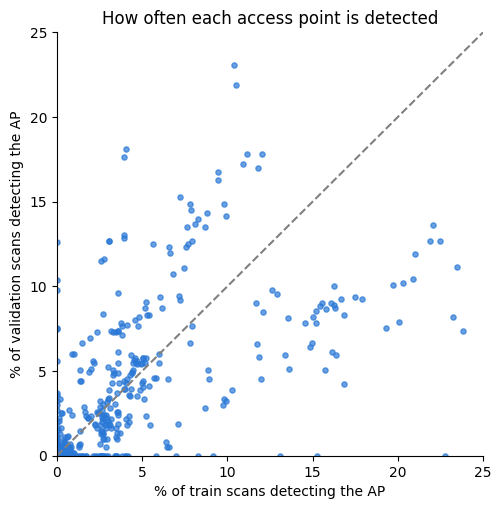

Correlation between train and validation detection rates: 0.64


In [33]:
# % of scans in which each access point is detected
rate_tr = (X_tr != 100).mean() * 100
rate_va = (X_va != 100).mean() * 100

plt.figure(figsize=(5.5, 5.5))
plt.scatter(rate_tr, rate_va, s=14, color=BLUE, alpha=0.7)
plt.plot([0, 25], [0, 25], "--", color="grey")
plt.xlim(0, 25)
plt.ylim(0, 25)
plt.xlabel("% of train scans detecting the AP")
plt.ylabel("% of validation scans detecting the AP")
plt.title("How often each access point is detected")
plt.savefig(FIG + "eda_wap_detection_train_vs_val.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Correlation between train and validation detection rates: {rate_tr.corr(rate_va):.2f}")

Each dot is one access point. On the dashed line it is detected equally often in both files. The correlation
is only 0.64, so many access points behave quite differently between the files.

Below, the **KS statistic** measures how different two distributions are (0 = identical, 1 = completely
different). Because we have so much data, the p-values are always tiny, so we look at the KS value itself:
below about 0.1 is a small difference.

In [34]:
from scipy.stats import ks_2samp

rows = []
for name, a, b in [("APs detected per scan", aps_tr, aps_va),
                   ("Strongest signal per scan", strongest_tr.dropna(), strongest_va.dropna()),
                   ("All signal readings", rssi_tr, rssi_va)]:
    result = ks_2samp(a, b)
    rows.append({"quantity": name, "KS statistic": round(result.statistic, 3), "p-value": f"{result.pvalue:.1e}"})

shift = pd.DataFrame(rows).set_index("quantity")
shift.to_csv(METRICS + "eda_train_val_shift.csv")
shift

,KS statistic,p-value
quantity,,
APs detected per scan,0.131,3.1e-16
Strongest signal per scan,0.079,4.2e-06
All signal readings,0.057,4.0e-49


The number of APs per scan has shifted moderately (KS = 0.13; validation scans detect fewer APs). Signal
strength has shifted only slightly (KS = 0.06–0.08).

### 6.5 Leakage risks

**Leakage** means information from the test data sneaks into training, so results look better than they really
are. The main risk here is that each position was scanned many times.

In [35]:
# a label for each unique position
position = (train["BUILDINGID"].astype(str) + "_" + train["FLOOR"].astype(str) + "_" +
            train["LONGITUDE"].astype(str) + "_" + train["LATITUDE"].astype(str))

print("Training positions:", position.nunique())
print("Median scans per position:", position.value_counts().median())

users_per_position = train.groupby(position)["USERID"].nunique()
print(f"Positions scanned by more than one user: {(users_per_position > 1).mean() * 100:.1f}%")

same = pd.merge(X_va, X_tr.drop_duplicates(), on=WAP_COLS)
print("Validation scans identical to a training scan:", len(same))

Training positions: 933
Median scans per position: 20.0
Positions scanned by more than one user: 77.9%
Validation scans identical to a training scan: 0


In [36]:
from sklearn.model_selection import KFold, GroupKFold

def position_overlap(splitter, groups=None):
    # % of test-fold scans whose position also appears in the training fold
    results = []
    for train_idx, test_idx in splitter.split(train, groups=groups):
        seen = set(position.iloc[train_idx])
        results.append(position.iloc[test_idx].isin(seen).mean())
    return round(np.mean(results) * 100, 1)

print("Random 5-fold:           ", position_overlap(KFold(5, shuffle=True, random_state=42)), "%")
print("Grouped by position:     ", position_overlap(GroupKFold(5), groups=position), "%")
print("Grouped by user:         ", position_overlap(GroupKFold(5), groups=train["USERID"]), "%")

Random 5-fold:            100.0 %
Grouped by position:      0.0 %
Grouped by user:          67.3 %


**What this shows**
- Each position was scanned about **20 times**. With a normal random 5-fold split, **100%** of the test scans
  are at a position the model already saw in training, so the scores would be far too optimistic.
- Splitting **by position** removes this completely (0%).
- Splitting **by user** is in between (67.3%), because most positions were scanned by several users.
- No validation scan is identical to a training scan, so the official split is safe.

**Recommended way to test models**
1. **Final results:** train on the training file and test once on the validation file.
2. **Tuning:** use `GroupKFold` inside the training file, grouped by position (never a random split).
3. **Extra robustness test:** `GroupKFold` grouped by user (which also means a new phone).

**Other things to avoid**
- Never use `SPACEID` or `RELATIVEPOSITION` as inputs: they describe the room, which is basically the answer.
- Fit all preprocessing (filling in 100s, scaling, dropping columns) on training data only.
- Drop duplicates before splitting, or keep copies together in the same fold.

## 7. Summary

**The data is reliable:** no invalid values, valid labels, clearly separated buildings, and every
building–floor has at least 948 training scans.

**What makes it hard:**
1. **Sparse signals:** 96.5% of values are "not detected"; a scan sees only about 17 of 520 access points.
2. **Differences between the files:** collected 91 days apart, mostly with different phones (only 2 of 11
   shared), focusing on different buildings, and with some access points that appear in only one file.
   We should expect lower scores on validation than inside the training data.
3. **Phone differences:** phones disagree by about 15 dB in signal strength, and one phone (19) gives
   unrealistic readings.

**Recommendations**

| Area | Recommendation |
|---|---|
| Preprocessing | Replace 100 with about −110; add "detected / not detected" indicators; drop the 55 never-detected APs; remove the 76 empty scans; decide on the 637 duplicates; cap readings at −30 dBm; add "number of APs" and "strongest signal" features; fit everything on train only |
| Models | Beat the simple baselines (building 47.6%, floor 25.3%); tune with position-grouped CV, never random CV |
| Evaluation | Report macro-F1 and results per building and per phone; check whether the 35 poorly covered validation scans have the biggest errors |
| Everyone | Use the validation file only once, for the final results |